```markdown
# Aula: Desvendando o Agrupamento de Dados (Clustering)

Bem-vindo à nossa aula prática sobre **Clustering** (Agrupamento)! Este notebook foi projetado para quem está dando os primeiros passos em Aprendizado de Máquina (Machine Learning) e deseja entender como os computadores conseguem encontrar padrões e agrupar informações sem precisar de respostas prontas.

Nesta aula, utilizaremos o famoso conjunto de dados *Iris* para explorar e comparar três dos algoritmos de agrupamento mais importantes do mercado: **K-Means**, **DBSCAN** e **Agrupamento Hierárquico (Hierarchical Clustering)**.

---

## 🎯 Objetivos de Aprendizagem
Ao final deste notebook, você será capaz de:
1. **Compreender o conceito de Aprendizado Não Supervisionado**, onde o modelo aprende a agrupar dados sem rótulos previamente definidos.
2. **Diferenciar o funcionamento prático** dos algoritmos K-Means, DBSCAN e Agrupamento Hierárquico.
3. **Interpretar Matrizes de Confusão** e gráficos de dispersão (Scatter Plots) aplicados à validação de clusters.
4. **Analisar um Dendrograma** para decidir visualmente o número ideal de grupos em um agrupamento hierárquico.

---

## 🛠️ Pré-requisitos e Ferramentas Utilizadas
Para executar os experimentos, utilizamos as seguintes bibliotecas do ecossistema Python:

*   **`sklearn` (Scikit-Learn):** A biblioteca líder para Machine Learning em Python. Dela, usamos o módulo `datasets` para carregar nossos dados de teste, `metrics` para avaliar a qualidade dos grupos, e `cluster` que contém as implementações dos algoritmos.
*   **`matplotlib.pyplot`:** Ferramenta essencial para gerar os gráficos que nos ajudam a "enxergar" como os algoritmos dividiram as flores.
*   **`scipy.cluster.hierarchy`:** Biblioteca científica que nos fornece funções matemáticas específicas para construir e desenhar o mapa de conexões (dendrograma) do agrupamento hierárquico.
```

In [1]:
from sklearn import datasets
from sklearn.metrics import confusion_matrix
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

```markdown
## Passo 1: Carregando e Entendendo a Base de Dados (Iris Dataset)

Antes de aplicar qualquer inteligência artificial, precisamos entender a matéria-prima: os dados.

O dataset **Iris** é um clássico da estatística e do ML. Ele contém medições físicas de 150 flores de três espécies diferentes de plantas Iris (*Setosa*, *Versicolor* e *Virginica*). As quatro características medidas são:
1. Comprimento da sépala (sepal length)
2. Largura da sépala (sepal width)
3. Comprimento da pétala (petal length)
4. Largura da pétala (petal width)

*Nota didática:* Embora saibamos de antemão a espécie de cada flor (isso está guardado em `iris.target`), nós **escondemos** essa informação dos algoritmos de clusterização. Eles tentarão agrupar as flores usando apenas as características físicas!
```

In [2]:
iris = datasets.load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

```markdown
## Passo 2: Criando nossa Função de Visualização

Como estamos trabalhando com 4 dimensões (4 medidas físicas), é impossível para o cérebro humano visualizar tudo de uma vez em um gráfico bidimensional comum.

Para facilitar nosso estudo, a função abaixo projeta os dados em duas dimensões principais: o **Comprimento da Sépala** (eixo X) e a **Largura da Pétala** (eixo Y). Ela pinta os pontos com cores diferentes de acordo com o grupo (cluster) que o algoritmo definiu, além de identificar de forma especial os ruídos (pontos que não pertencem a nenhum grupo).
```

In [3]:
def plot_clusters(data, labels, title):
  colors = ['red','green','purple','black']
  plt.figure(figsize=(8,4))
  for i,c,l in zip(range(-1,3), colors, ['Noise','Setosa','Versicolor','Virginica']):
    if i == -1:
      plt.scatter(data[labels == i, 0], data[labels == i, 3], c=colors[i], label = l, alpha=0.5, s=50, marker='x')
    else:
      plt.scatter(data[labels == i, 0], data[labels == i, 3], c=colors[i], label = l, alpha=0.5, s=50)
  plt.legend()
  plt.title(title)
  plt.xlabel('Comprimento Sépala')
  plt.ylabel("Largura da Pétala")
  plt.show()

```markdown
💡 **Para pensar:**
Na função `plot_clusters`, as cores e as legendas de espécie ('Setosa', 'Versicolor', 'Virginica') estão fixas para os índices dos clusters gerados. No entanto, algoritmos de clustering não sabem os nomes reais das classes; eles apenas atribuem números arbitrários (0, 1, 2). Se o algoritmo associar o cluster `0` à *Versicolor*, o gráfico pode acabar rotulando incorretamente a legenda visual, embora a separação geométrica dos pontos continue correta.
```

In [4]:
iris.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

```markdown
## Passo 3: Algoritmo K-Means

O **K-Means** é o algoritmo de agrupamento mais popular. O seu funcionamento básico segue estes passos:
1. Você define o valor de $K$ (número de grupos que deseja, no nosso caso, `n_clusters=3`).
2. O algoritmo joga 3 pontos aleatórios no gráfico (chamados de *centroides*).
3. Ele associa cada flor ao centroide mais próximo.
4. Ele recalcula a posição do centroide para o centro físico do grupo formado.
5. Repete os passos 3 e 4 até que os grupos parem de mudar.

Vamos rodar o K-Means e observar a **Matriz de Confusão** para ver como ele se saiu em comparação com a classificação real da natureza.
```

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 2 2 2 1 2 2 2 2
 2 2 1 1 2 2 2 2 1 2 1 2 1 2 2 1 1 2 2 2 2 2 1 2 2 2 2 1 2 2 2 1 2 2 2 1 2
 2 1]
[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]


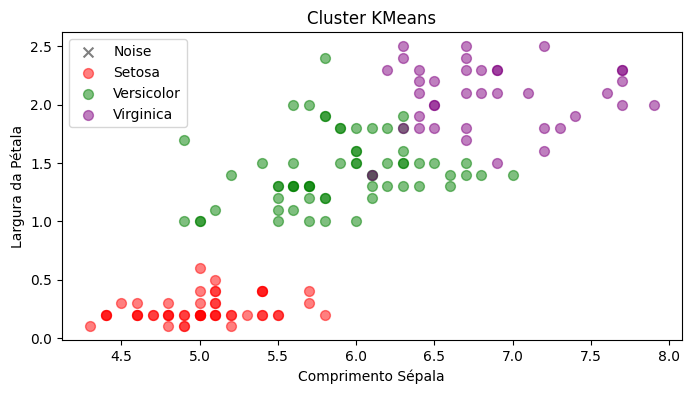

In [5]:
kmeans = KMeans(n_clusters=3,n_init='auto')
kmeans.fit(iris.data)
print(kmeans.labels_)
resultados = confusion_matrix(iris.target, kmeans.labels_)
print(resultados)

plot_clusters(iris.data, kmeans.labels_, 'Cluster KMeans')

```markdown
### 📊 Interpretando o K-Means

*   **Matriz de Confusão:** Seus resultados mostram que o grupo da flor *Setosa* (linha 1) foi separado com perfeição absoluta (50 de 50). Já entre *Versicolor* e *Virginica*, houve uma pequena confusão (algumas flores de uma espécie foram agrupadas junto com a outra) porque as características físicas delas se sobrepõem na natureza.
*   **Visualização Gráfica:** Note no gráfico gerado como a separação dos grupos parece seguir linhas ou fronteiras bem definidas entre as cores.
```

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  2  1  1  2  1  1  1  1  1  1  1 -1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  2  1  1
  1  1  2  1  1  1  1  1  1  3 -1  1 -1 -1  1  1  1  1  1  1  1 -1  3  1
  1  1  3  1  1  1  1  1  1  1  1 -1  1  1 -1 -1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]


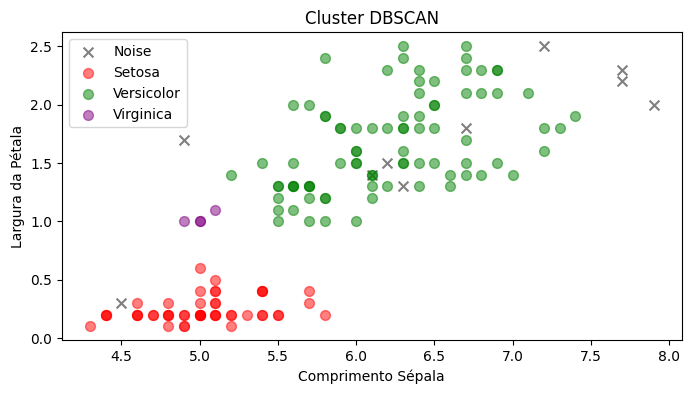

In [6]:
dbscan = DBSCAN(eps=0.5, min_samples=3)
dbscan_labels = dbscan.fit_predict(iris.data)
print(dbscan_labels)

plot_clusters(iris.data, dbscan_labels, 'Cluster DBSCAN')

```markdown
## Passo 4: Algoritmo DBSCAN (Density-Based Spatial Clustering)

Diferente do K-Means, o **DBSCAN** não exige que você diga quantos grupos quer no início. Ele funciona por **densidade de pontos**:
*   Ele procura regiões onde há muitos pontos próximos (alta densidade).
*   **`eps` (Epsilon):** Define o raio máximo de distância para que dois pontos sejam considerados vizinhos.
*   **`min_samples`:** O número mínimo de pontos vizinhos para formar um grupo de alta densidade.
*   **Ruído (Noise):** Pontos isolados que não alcançam essa densidade mínima são marcados com o rótulo `-1` e representados com um "X" cinza no gráfico.
```

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[[ 0 50  0]
 [49  0  1]
 [15  0 35]]


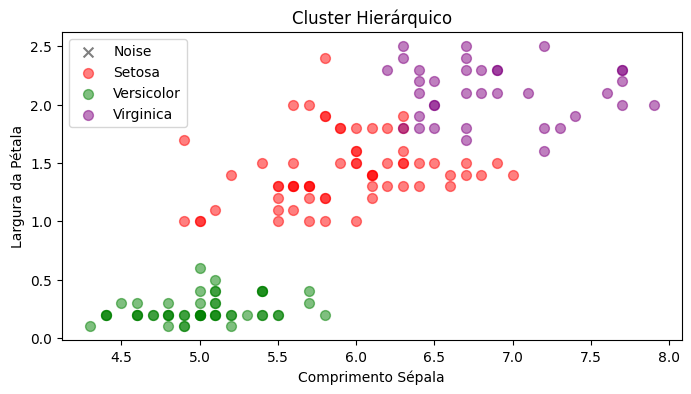

In [7]:
agglo = AgglomerativeClustering(n_clusters=3)
agglo_labels = agglo.fit_predict(iris.data)
print(agglo_labels)
resultados = confusion_matrix(iris.target,agglo_labels)
print(resultados)
plot_clusters(iris.data,agglo_labels,'Cluster Hierárquico' )

```markdown
### 📊 Interpretando o DBSCAN e o Agrupamento Hierárquico

*   **No DBSCAN:** Perceba como ele identificou vários pontos como ruído (`-1`). O DBSCAN é excelente para encontrar grupos de formatos geométricos complexos e para ignorar dados atípicos (*outliers*).
*   **No Agrupamento Hierárquico:** Este método funciona de maneira aglomerativa (de baixo para cima). Ele começa tratando cada ponto como um grupo individual e vai juntando os grupos mais próximos de forma gradual, até que tudo esteja unificado.
```

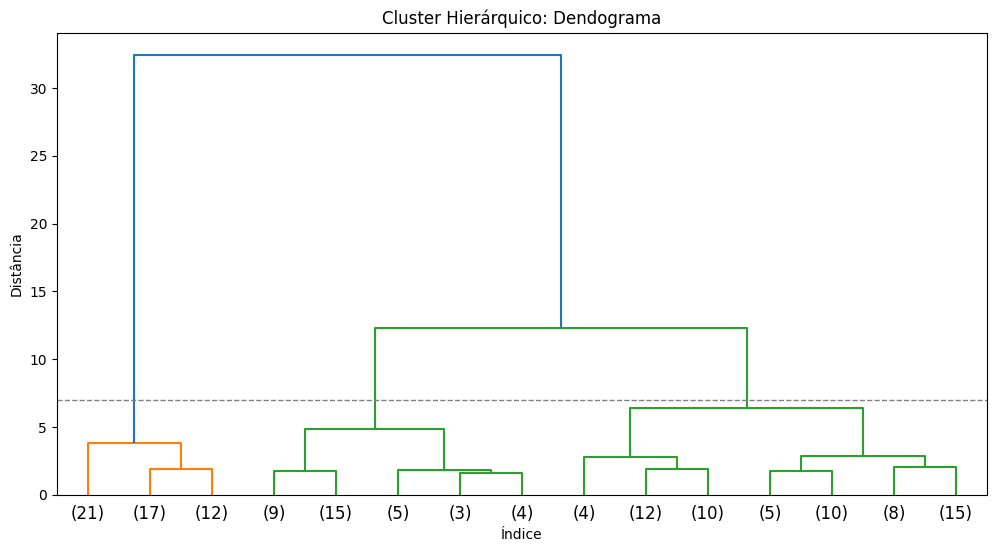

In [8]:
plt.figure(figsize=(12,6))
plt.title("Cluster Hierárquico: Dendograma")
plt.xlabel("Índice")
plt.ylabel("Distância")
linkage_matrix = linkage(iris.data, method='ward')
dendrogram(linkage_matrix, truncate_mode='lastp', p=15)
plt.axhline(y=7, c='gray', lw=1, linestyle='dashed')
plt.show()

```markdown
## Passo 5: Analisando o Dendrograma

O **Dendrograma** é uma árvore genealógica dos seus dados. No eixo vertical (Y), temos a distância matemática que separa os grupos.

*   A linha tracejada cinza horizontal plotada na altura `y=7` nos ajuda a decidir onde "cortar" a árvore.
*   Ao cortar a árvore nessa altura, o número de linhas verticais interceptadas nos diz quantos grupos ideais deveríamos criar. No nosso caso, o corte sugere que 3 grupos é uma divisão muito robusta e natural para esses dados.

---

## ⚠️ Erros Comuns e Dicas de Sobrevivência

1.  **Não escalar os dados:** Algoritmos baseados em distância (como K-Means e Hierárquico) são altamente sensíveis à escala das variáveis. Se uma coluna estiver na casa dos milhares (ex: salário) e outra na casa decimal (ex: idade), o algoritmo vai ignorar a idade. Use `StandardScaler` do scikit-learn antes de começar!
2.  **Escolher o 'K' errado:** Definir um K aleatório no K-Means pode arruinar o modelo. Utilize técnicas como o *Método do Cotovelo* (Elbow Method) ou a *Silhueta* para encontrar o melhor número.
3.  **Ajustar mal o `eps` no DBSCAN:** Um Epsilon muito pequeno fará com que quase tudo vire ruído (`-1`). Um Epsilon muito grande unirá a base inteira em um único grupo gigante.

---

## 🏁 Resumo da Aprendizagem

*   **Aprendizado Não Supervisionado:** Não precisamos de respostas corretas estruturadas; o algoritmo foca em proximidade e semelhança.
*   **K-Means:** Rápido, mas exige a escolha de $K$ de antemão e assume que os grupos são esféricos e bem definidos.
*   **DBSCAN:** Excelente para ruídos e agrupamentos de formatos arbitrários, mas sensível a parâmetros de densidade.
*   **Hierárquico:** Visualização incrível por meio do dendrograma, excelente para entender a hierarquia interna dos seus dados.

---

## 📝 Exercícios Propostos

1.  **Fácil:** Mude o valor de `n_clusters` no código do K-Means de 3 para 2 e depois para 5. Observe o que acontece com a divisão no gráfico.
2.  **Médio:** No DBSCAN, altere o parâmetro `eps` para `0.3` e depois para `1.0`. Explique o impacto dessa mudança no volume de pontos classificados como ruído (`Noise`).
3.  **Desafiador:** Importe a classe `StandardScaler` do `sklearn.preprocessing`, aplique-a sobre `iris.data` antes de rodar os modelos e compare se as matrizes de confusão melhoraram ou pioraram.

---

## 🚀 Para ir além (Tópicos para Pesquisar)

*   **Método do Cotovelo (Elbow Method):** Saiba como determinar matematicamente o melhor valor de K para o seu dataset.
*   **Coeficiente de Silhueta (Silhouette Score):** Uma métrica robusta para avaliar o quão bem separados estão seus clusters sem depender das classes originais do dataset.
*   **Algoritmo HDBSCAN:** Uma evolução do DBSCAN que consegue encontrar clusters de diferentes densidades automaticamente.
```